# 5 · The official alert, next to the radar

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/agent-engineering-studio/dpc-radar/blob/main/notebooks/05_alert_vs_radar.ipynb)

Every afternoon the Civil Protection Department publishes the **criticality bulletin**: for
each alert zone of Italy, a colour for today and one for tomorrow. Green, yellow, orange,
red. It is the **official** alert, the one mayors act on.

The bulletin is open data too (CC BY 4.0, on the Department's GitHub). `dpc_radar.bulletins`
reads it as data: no web page to scrape, no PDF.

This notebook puts the two side by side: **what was announced** and **what fell**.

> A radar map is a measurement, not an alert. Show it *next to* the official bulletin,
> never *instead of* it.

In [1]:
# On Colab (or any fresh environment) this installs the library; at home it does nothing.
import importlib.util

if importlib.util.find_spec("dpc_radar") is None:
    %pip install -q "dpc-radar[bulletins]" matplotlib

In [2]:
# Drawing helpers: a rain map in the colours of the README. Skip on a first read.
import json
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from rasterio.transform import array_bounds
from rasterio.warp import Resampling, calculate_default_transform, reproject

DATA = Path("data")  # downloads are kept here, so a second run is fast
DATA.mkdir(exist_ok=True)
BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
LAND, BORDER, UNMEASURED = "#ecebe6", "#6f6e69", "#bdbcb6"
ITALY = (6.0, 36.3, 19.0, 47.3)  # west, south, east, north
CREDIT = "Data © Dipartimento della Protezione Civile, CC BY-SA 4.0 · borders: Natural Earth"
BORDERS_URL = (
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/"
    "geojson/ne_50m_admin_0_countries.geojson"
)


def borders():
    """The outline of every country, from Natural Earth (public domain)."""
    file = DATA / "countries.geojson"
    if not file.exists():
        file.write_bytes(httpx.get(BORDERS_URL, timeout=120, follow_redirects=True).content)
    rings = []
    for feature in json.loads(file.read_text())["features"]:
        geom = feature["geometry"]
        polygons = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        rings += [np.array(polygon[0]) for polygon in polygons]
    return rings


def lonlat(grid):
    """The pixels of a frame on a longitude/latitude grid, and its corners."""
    data, transform = grid.data, grid.transform
    if grid.crs.to_epsg() != 4326:  # SRI and SRT1 use a projection in metres
        h, w = data.shape
        bounds = array_bounds(h, w, transform)
        transform, w, h = calculate_default_transform(grid.crs, "EPSG:4326", w, h, *bounds)
        data = np.full((h, w), np.nan, dtype="float32")
        reproject(
            grid.data,
            data,
            src_transform=grid.transform,
            src_crs=grid.crs,
            dst_transform=transform,
            dst_crs="EPSG:4326",
            src_nodata=np.nan,
            dst_nodata=np.nan,
            resampling=Resampling.nearest,
        )
    west, south, east, north = array_bounds(*data.shape, transform)
    return data, (west, east, south, north)


def rain_map(grid, ax, levels, *, box=ITALY, title="", unit="mm"):
    """Draw one frame: blue where it rained, grey where the radar did not measure."""
    data, extent = lonlat(grid)
    cmap = ListedColormap(BLUE)
    cmap.set_under("none")  # less than the first level: show the land
    cmap.set_bad(UNMEASURED)  # NaN: not measured, which is not the same as dry
    norm = BoundaryNorm(levels, cmap.N, extend="max")
    ax.set_facecolor("white")
    for ring in borders():
        ax.fill(ring[:, 0], ring[:, 1], color=LAND, zorder=0)
        ax.plot(ring[:, 0], ring[:, 1], color=BORDER, linewidth=0.6, zorder=3)
    image = ax.imshow(data, extent=extent, cmap=cmap, norm=norm, interpolation="nearest", zorder=2)
    ax.set_xlim(box[0], box[2])
    ax.set_ylim(box[1], box[3])
    ax.set_aspect(1.3)  # a degree of longitude is shorter than one of latitude here
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, loc="left", fontsize=11)
    bar = plt.colorbar(image, ax=ax, shrink=0.6, pad=0.02, ticks=levels)
    bar.set_label(unit)
    ax.plot([], [], "s", color=UNMEASURED, label="not measured")
    ax.legend(loc="lower left", fontsize=8, frameon=False, handletextpad=0.2)
    return image

## Today's bulletin

In [3]:
from dpc_radar import bulletins

today = await bulletins.latest()
print("issued :", today.issued.strftime("%d %B %Y at %H:%M"), "(Italian time)")
print("days   :", ", ".join(str(d) for d in today.days()))
for day in today.days():
    alerts = today.alerts(day)
    count = {c: sum(z.colour == c for z in alerts) for c in ("red", "orange", "yellow")}
    print(f"{day}: {count['red']} red, {count['orange']} orange, {count['yellow']} yellow zones")

issued : 15 November 2026 at 14:21 (Italian time)
days   : 2026-11-15, 2026-11-16
2026-11-15: 0 red, 0 orange, 30 yellow zones
2026-11-16: 0 red, 0 orange, 36 yellow zones


Each zone carries three separate risks: **hydro-geological** (landslides, small streams),
**hydraulic** (large rivers) and **thunderstorms**. The colour on the map is the highest of
the three. `zone_at` finds the zone of a place.

In [4]:
names = {0: "none", 1: "yellow", 2: "orange", 3: "red"}
for city, (lon, lat) in {"Roma": (12.50, 41.90), "Genova": (8.95, 44.41)}.items():
    zone = today.zone_at(lon, lat)
    print(f"{city} is in the zone «{zone.name}»: {zone.colour}")
    print(
        f"   landslides {names[zone.hydrogeological]}, rivers {names[zone.hydraulic]},",
        f"thunderstorms {names[zone.thunderstorms]}; {len(zone.municipalities)} municipalities",
    )

Roma is in the zone «Bacini di Roma»: none
   landslides none, rivers none, thunderstorms none; 27 municipalities
Genova is in the zone «Bacini Liguri Marittimi di Centro»: none
   landslides none, rivers none, thunderstorms none; 27 municipalities


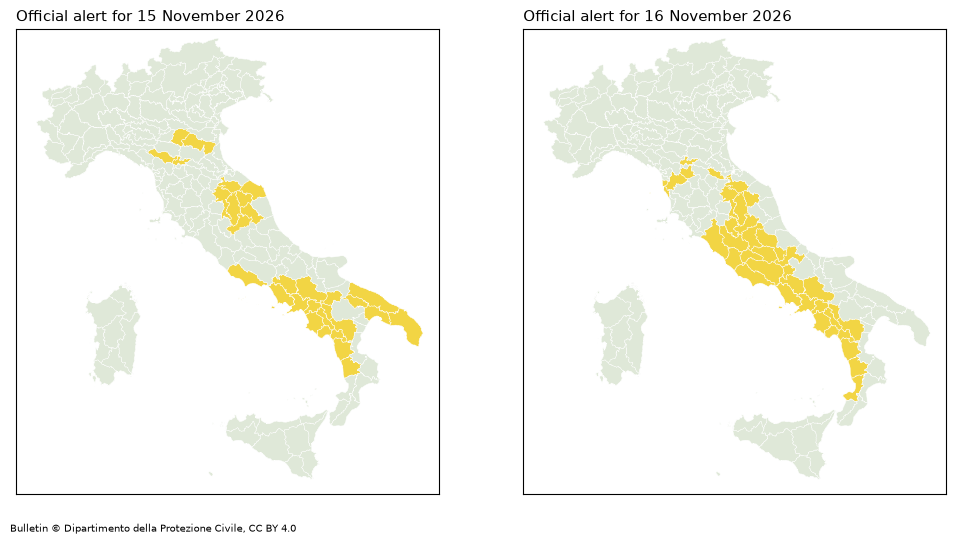

In [5]:
ALERT = {0: "#dfe8d8", 1: "#f2d544", 2: "#f08a24", 3: "#d7301f"}


def alert_map(bulletin, day, ax, *, box=ITALY, title=""):
    """The zones of one day, in the colour of their alert."""
    for zone in bulletin.zones:
        if zone.valid != day:
            continue
        for polygon in zone.geometry.geoms:
            x, y = polygon.exterior.xy
            ax.fill(x, y, color=ALERT[zone.level], edgecolor="white", linewidth=0.3)
    ax.set_xlim(box[0], box[2])
    ax.set_ylim(box[1], box[3])
    ax.set_aspect(1.3)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, loc="left", fontsize=11)


fig, axes = plt.subplots(1, 2, figsize=(12, 6.5))
for ax, day in zip(axes, today.days(), strict=False):
    alert_map(today, day, ax, title=f"Official alert for {day:%d %B %Y}")
fig.text(0.12, 0.08, "Bulletin © Dipartimento della Protezione Civile, CC BY 4.0", fontsize=7)
plt.show()

## A day we know: 10 October 2026

The bulletins of the past stay in the repository, so a past day can be studied. The one
issued on the afternoon of **9 October** said, for the next day, what to expect on the
southern tip of Calabria.

In [6]:
from datetime import UTC, date, datetime

DAY = date(2026, 10, 10)
MELITO = (15.78, 37.92)

eve = await bulletins.fetch("20261009_1615_today.json")
zone = eve.zone_at(*MELITO, DAY)
print("issued :", eve.issued.strftime("%d %B %Y at %H:%M"))
print(f"zone   : «{zone.name}», {len(zone.municipalities)} municipalities")
print(f"alert for {DAY}: {zone.colour.upper()}")
print(
    f"   landslides {names[zone.hydrogeological]}, rivers {names[zone.hydraulic]},",
    f"thunderstorms {names[zone.thunderstorms]}",
)

issued : 09 October 2026 at 16:15
zone   : «Versante Jonico Meridionale», 120 municipalities
alert for 2026-10-10: ORANGE
   landslides orange, rivers orange, thunderstorms orange


Orange, the day before. Now the measurement: the «Merging» of the 24 hours of that day.

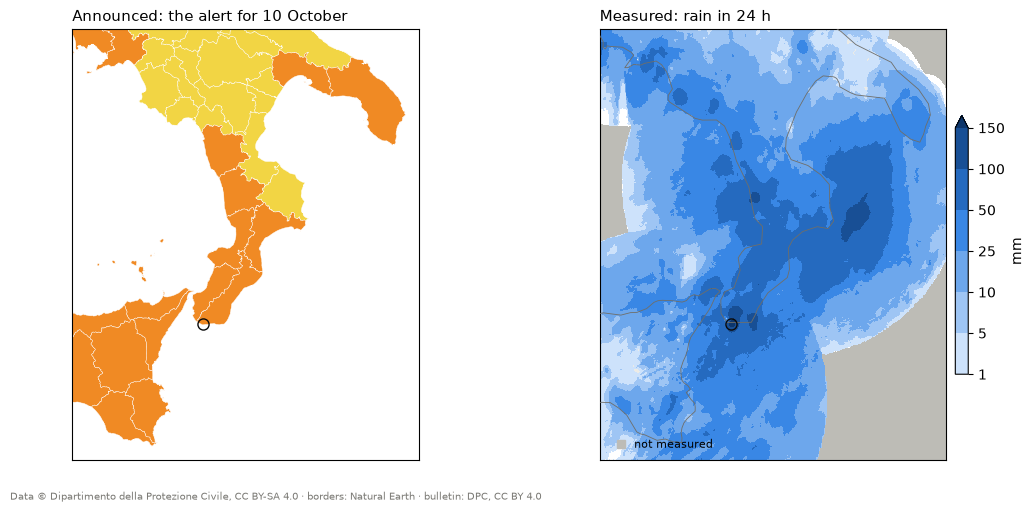

Melito di Porto Salvo: 192 mm in 24 hours


In [7]:
from dpc_radar import ABSENT, RadarClient

async with RadarClient() as radar:
    rain = await radar.at("CUM24", datetime(2026, 10, 11, tzinfo=UTC))
if rain is ABSENT:
    raise SystemExit("The DPC no longer keeps this frame: choose a more recent day.")

SOUTH = (14.0, 36.5, 18.7, 41.0)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
alert_map(eve, DAY, axes[0], box=SOUTH, title="Announced: the alert for 10 October")
rain_map(rain, axes[1], [1, 5, 10, 25, 50, 100, 150], box=SOUTH, title="Measured: rain in 24 h")
for ax in axes:
    ax.plot(*MELITO, marker="o", ms=8, mfc="none", mec="#0b0b0b", zorder=5)
fig.text(0.12, 0.04, CREDIT + " · bulletin: DPC, CC BY 4.0", fontsize=7, color="#7a7974")
plt.show()
print(f"Melito di Porto Salvo: {rain.sample([MELITO])[0]:.0f} mm in 24 hours")

## Zone by zone

For every zone of that day: its colour, and the rain measured inside it. The shape of the
zone selects its pixels; we keep their **average** (the rain on the whole zone) and their
**highest** value (the worst square kilometre).

In [8]:
from rasterio.features import geometry_mask


def rain_in(zone):
    """Average and highest rain on the pixels inside a zone, or None if none is measured."""
    part = rain.crop(zone.geometry.bounds)
    inside = geometry_mask([zone.geometry], part.data.shape, part.transform, invert=True)
    values = part.data[inside & np.isfinite(part.data)]
    return (float(values.mean()), float(values.max())) if values.size else None


rows = []
for zone in eve.zones:
    if zone.valid == DAY and (found := rain_in(zone)):
        rows.append((zone.level, *found, zone.name))

print(f"{'alert':<8}{'zones':>6}{'typical average':>18}{'typical peak':>15}")
for level in (3, 2, 1, 0):
    group = [(mean, top) for lv, mean, top, _ in rows if lv == level]
    if group:
        mean, top = np.median(group, axis=0)
        print(f"{names[level]:<8}{len(group):>6}{mean:>15.0f} mm{top:>12.0f} mm")

print()
print("The five wettest zones (average rain on the zone):")
for level, mean, top, name in sorted(rows, key=lambda r: -r[1])[:5]:
    print(f"  {mean:4.0f} mm (peak {top:3.0f})   {names[level]:<7} {name}")

alert    zones   typical average   typical peak
orange      19             28 mm          75 mm
yellow      40             11 mm          28 mm
none       128              0 mm           0 mm

The five wettest zones (average rain on the zone):
    75 mm (peak 207)   orange  Versante Jonico Meridionale
    60 mm (peak 126)   orange  Versante Tirrenico Meridionale
    58 mm (peak 126)   orange  Versante Tirrenico Centro-settentrionale
    56 mm (peak  75)   orange  Versante Jionico Centro-meridionale
    56 mm (peak  78)   orange  Versante Tirrenico Centro-meridionale


Read it both ways. Where the alert was higher, more rain fell: the bulletin pointed in the
right direction. And no colour says *how many millimetres*: the same orange covers zones
where the worst square kilometre got 75 mm and one where it got more than 200. The two sources answer different questions, which is why
they belong on the same screen.

## What you have seen

- `await bulletins.latest()` reads the official alert of today and tomorrow;
- `bulletin.zone_at(lon, lat)` finds the zone and the colour of a place;
- `bulletin.alerts(day, at_least=2)` lists the zones from orange up;
- `await bulletins.fetch(name)` reads a bulletin of the past.

Unsigned requests to GitHub are limited to 60 an hour: `latest()` uses three, `fetch()` none.

*Bulletins © Dipartimento della Protezione Civile, CC BY 4.0. Radar data © Dipartimento della
Protezione Civile, CC BY-SA 4.0. This notebook is not an alert service.*